In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.3 割り込みベクタ (`Interrupt Vectors in x86-64`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.3_Interrupt_Vectors_in_x86_64.ipynb)
![Language](https://img.shields.io/badge/Language-C%2B%2B20%20%7C%20Python%203.10%2B-blue.svg)
![Target](https://img.shields.io/badge/Target-x86__64%20%7C%20UEFI-orange.svg)
![Status](https://img.shields.io/badge/Status-Completed-brightgreen.svg)

---

## 📖 本節の概要と学習目標

前節（7.2 割り込みハンドラ）では、割り込み発生時に CPU がスタックへ退避するハードウェアスタックフレーム（`InterruptFrame`）のメモリ構造、`__attribute__((interrupt))` による汎用レジスタ全保護と 16 バイトアライメント補正、そして `IRETQ` 命令によるアトミックな復帰処理を学びました。

しかし、PC にはマウスやキーボード（USB / xHCI）、タイマ（Local APIC Timer）、ストレージ（NVMe / SATA）、ネットワークカード（NIC）など、数多くの周辺機器が接続されています。また、プログラム実行中には「ゼロ除算」や「存在しないメモリへのアクセス（ページフォルト）」といった CPU 自身の異常も発生します。

> [!IMPORTANT]
> **本節の核心的問い**:
> 1. CPU は、発生した割り込みや例外が「どのデバイス」「どのエラー」によるものかを、どのように識別しているのか？
> 2. x86-64 アーキテクチャで規定された 256 個の「割り込みベクタ番号（0〜255）」は、どのように分類・設計されているのか？
> 3. CPU 例外の 3 大分類（`Fault`, `Trap`, `Abort`）によって、ハードウェア動作やスタックフレーム、復帰動作はどう異なるのか？
> 4. なぜ MikanOS は、xHCI（USB 3.0 ホストコントローラ）の割り込みベクタ番号として **`0x40` (64)** を選んだのか？

本節を通じて、x86-64 のハードウェア仕様に基づくベクタ割り当て理論と、MikanOS における C++ クラス設計の真意を徹底的に解き明かします。


---

## 1. 割り込みベクタ（Interrupt Vector）とは何か？

**割り込みベクタ（Interrupt Vector）** とは、CPU が発生した割り込みや例外の種類を識別するための **`0` 〜 `255`（8 ビット整数、計 256 個）のインデックス番号** のことです。

CPU は外部ハードウェア（PCI デバイスの MSI や Local APIC）または内部回路から割り込み信号を受け取ると、信号に付随するベクタ番号（8-bit）を読み取ります。そして、メモリ上に配置された **IDT（*Interrupt Descriptor Table*: 割り込み記述子表）** の該当インデックスを参照し、そこに登録された割り込みハンドラのアドレスへジャンプします。

```text
+-----------------------+       ベクタ番号 (8-bit: 0〜255)
| 割り込み要因           | ------------------------------------+
| (xHCI, 例外, タイマ等) |                                     |
+-----------------------+                                     v
                                             +---------------------------------+
                                             | IDT (Interrupt Descriptor Table)|
                                             |                                 |
                                             | [0x00] #DE ハンドラ記述子       |
                                             | [0x01] #DB ハンドラ記述子       |
                                             |   ...                           |
                                             | [0x40] xHCI ハンドラ記述子 ---->|---> IntHandlerXHCI()
                                             |   ...                           |
                                             | [0xFF] 未使用                   |
                                             +---------------------------------+
```

ベクタ番号は単なる任意の数値ではなく、Intel / AMD の x86-64 アーキテクチャ仕様によって厳格な役割分担が定められています。


---

## 2. x86-64 割り込みベクタ空間の全体構造

x86-64 アーキテクチャにおける全 256 個のベクタは、大きく以下の 2 つの領域に分割されます：

### 2.1 ベクタ 0 〜 31 (0x00 〜 0x1F): CPU アーキテクチャ定義例外 (Architecture Exceptions)
- **CPU 内部で自動検知・発生する例外や障害** のために予約されています。
- OS 設計者がこの領域を外部周辺機器（マウスやキーボードなど）の割り込みに割り当てることは **絶対に禁止** されています。
- 代表例：
  - **ベクタ 0 (`#DE`)**: *Divide Error*（ゼロ除算）
  - **ベクタ 3 (`#BP`)**: *Breakpoint*（デバッガ用のブレークポイント `INT 3`）
  - **ベクタ 6 (`#UD`)**: *Invalid Opcode*（未定義・不正な機械語命令の実行）
  - **ベクタ 8 (`#DF`)**: *Double Fault*（二重障害：ハンドラ呼び出し中に追加の例外が発生）
  - **ベクタ 13 (`#GP`)**: *General Protection Fault*（一般保護例外：特権違反、未整列メモリアクセスなど）
  - **ベクタ 14 (`#PF`)**: *Page Fault*（ページフォルト：未マップ領域へのアクセス。第20章/27章の仮想メモリ・デマンドページングの根幹）

### 2.2 ベクタ 32 〜 255 (0x20 〜 0xFF): ユーザー定義 / 外部割り込み領域 (計 224 個)
- **OS の開発者が自由に周辺機器やソフトウェア割り込みに割り当て可能な領域** です。
- **ベクタ 32 〜 63 (`0x20` 〜 `0x3F`)**:
  - かつての PC/AT 互換機では、レガシーな割り込みコントローラ 8259 PIC (*Programmable Interrupt Controller*) の IRQ 0〜15 をリマップするために使われていた領域です。
- **ベクタ 64 (`0x40`)**:
  - **★ MikanOS が xHCI（USB 3.0 ホストコントローラ）の MSI 割り込みに採用したベクタ番号！**
- **ベクタ 65 〜 255 (`0x41` 〜 `0xFF`)**:
  - タイマ（Local APIC Timer）、PCI Express デバイス、OS のシステムコールなどに自由に利用できます。


---

## 3. 割り込みベクタ空間の完全マップ (Figure 7.05)

全 256 個のベクタ空間の区割りと、ベクタ 0〜31 の CPU 例外一覧テーブル、および MikanOS の採用設計を高解像度図版（Figure 7.05）として可視化します。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24828: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24830: UserWarning: Glyph 12450 (\N{KATAKANA LETTER A}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24830: UserWarning: Glyph 12540 (\N{KATAKANA-HIRAGANA PROLONGED SOUND MARK}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24830: UserWarning: Glyph 12461 (\N{KATAKANA LETTER KI}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(output_path, dpi=300, bbox_inches="tight")
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24830: UserWarning: Glyph 12486 (\N{KATAKANA LETTER TE}) missing from f

✅ Figure 7.05 を保存しました: /home/student/Documents/GitHub/study-mikanos/7/result/fig7_05_interrupt_vector_space_map.png


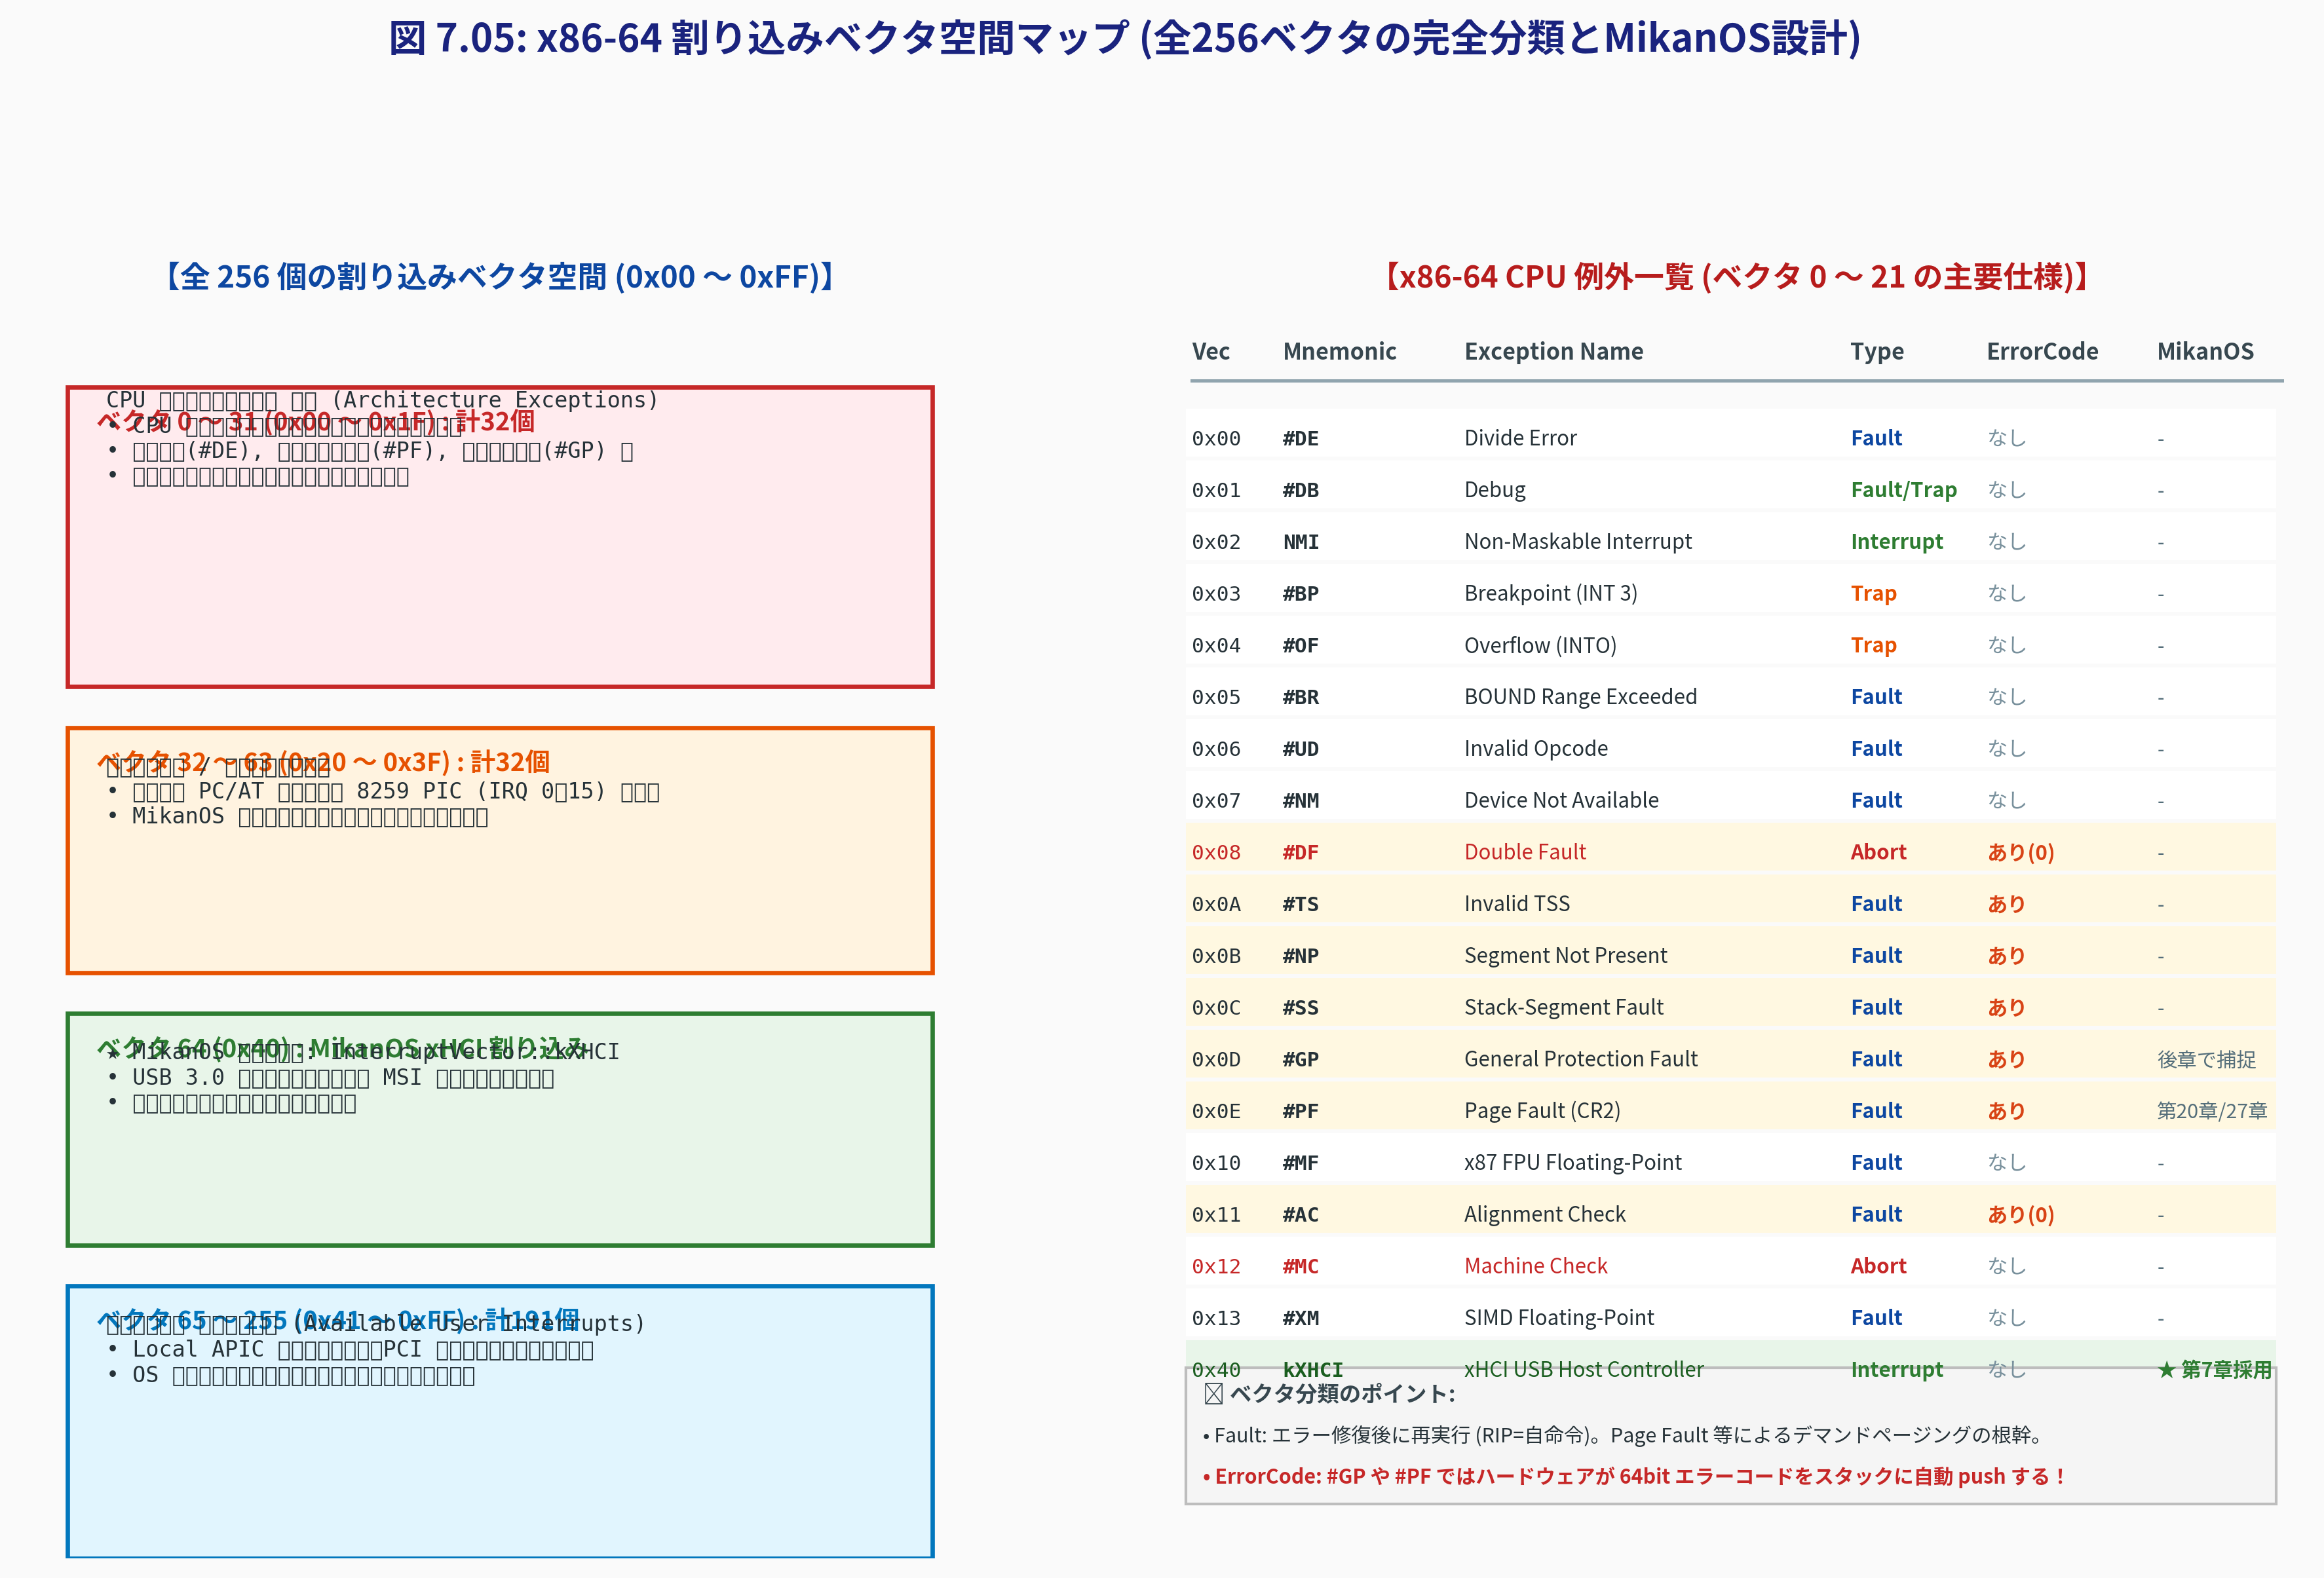

In [2]:
# === Figure 7.05: x86-64 割り込みベクタ空間マップの生成 & インライン表示 ===
import os
import matplotlib.pyplot as plt
from common import plot_interrupt_vector_space_map

fig_path = os.path.join(repo_root, "7", "result", "fig7_05_interrupt_vector_space_map.png")
plot_interrupt_vector_space_map(fig_path)

if os.path.exists(fig_path):
    print(f"✅ Figure 7.05 を保存しました: {fig_path}")
    from IPython.display import Image, display
    display(Image(filename=fig_path, width=950))
else:
    print("❌ 画像の生成に失敗しました。")


---

## 4. CPU 例外の 3 大分類とハードウェア動作

CPU が発生させる例外（ベクタ 0〜31）は、その発生タイミングと回復可能性に基づき、以下の **3 つのカテゴリ** に分類されます。

```text
+-------------------+--------------------------------+----------------------------+-----------------------+
| カテゴリ (Category)| 発生タイミング                 | 保存される RIP             | 復帰後の動作          |
+-------------------+--------------------------------+----------------------------+-----------------------+
| Fault (フォールト)| 命令の実行前または実行中       | 【例外を起こした命令自身】 | 命令を最初から再実行  |
| Trap (トラップ)   | 命令の実行完了直後             | 【次の命令】               | 次の命令から通常継続  |
| Abort (アボート)  | 回復不能な致命的障害           | 不確定 (信頼できない)      | 復帰不能 (HALT/Panic) |
+-------------------+--------------------------------+----------------------------+-----------------------+
```

### 4.1 Fault (フォールト: 命令再実行型)
- **代表例**: `#PF` (Page Fault, ベクタ 14), `#GP` (General Protection Fault, ベクタ 13), `#UD` (Invalid Opcode, ベクタ 6), `#DE` (Divide Error, ベクタ 0)
- **動作**:
  1. 命令が失敗した時点で CPU はその命令の実行を中断。
  2. スタックの `InterruptFrame.rip` には **「その命令自身のアドレス」** が退避されます。
  3. OS のハンドラが例外原因を解決（例: ページフォルト時にディスクから物理メモリへページをロード）して `IRETQ` を呼ぶと、CPU は **同一の命令をもう一度最初からやり直します**。修復されていれば命令は今度こそ成功し、プログラムは何事もなかったかのように進みます！

### 4.2 Trap (トラップ: 命令完了通知型)
- **代表例**: `#BP` (Breakpoint, ベクタ 3 / `INT 3`), `#OF` (Overflow, ベクタ 4 / `INTO`)
- **動作**:
  1. 命令の実行が正常に完了した直後に発生。
  2. スタックの `InterruptFrame.rip` には **「次の命令のアドレス」** が退避されます。
  3. デバッガや監視ツールが状態を記録・操作した後、`IRETQ` で復帰すると、プログラムは次の命令からスムーズに実行を継続します。

### 4.3 Abort (アボート: 回復不能障害型)
- **代表例**: `#DF` (Double Fault, ベクタ 8), `#MC` (Machine Check, ベクタ 18)
- **動作**:
  - システムを安全に継続できない物理エラー（ECC メモリエラーや、例外ハンドラ起動自体の失敗）です。
  - 保存される RIP はもはや意味をなさず、OS はカーネルパニック（ブルー画面 / 停止画面）を表示して `HLT` するしかありません。

---

### 4.4 ハードウェアによるエラーコード（ErrorCode）の自動プッシュ

ここで、低レイヤ OS 開発における **最大の罠（Pitfall）** が現れます。

大半の割り込みや例外では、CPU は `SS`, `RSP`, `RFLAGS`, `CS`, `RIP` の **5 つ（計 40 バイト）** をスタックにプッシュします（前節 7.2 で学んだ標準フレーム）。

しかし、以下の **特定例外** では、CPU ハードウェアが追加で **64 ビットのエラーコード（ErrorCode）** をスタックに自動プッシュします（合計 48 バイト）！

> [!WARNING]
> **エラーコードをプッシュする CPU 例外一覧**:
> - ベクタ 8: `#DF` (*Double Fault*) — 常に `0` を push
> - ベクタ 10: `#TS` (*Invalid TSS*) — TSS セグメントセレクタ番号
> - ベクタ 11: `#NP` (*Segment Not Present*) — セグメントセレクタ番号
> - ベクタ 12: `#SS` (*Stack-Segment Fault*) — スタックセグメントセレクタ番号
> - ベクタ 13: `#GP` (*General Protection Fault*) — 原因となったセレクタ番号または `0`
> - ベクタ 14: `#PF` (*Page Fault*) — フォールト理由ビット（P: 不在/保護, W/R: 読込/書込, U/S: ユーザー/カーネル, I/D: 命令フェッチ）
> - ベクタ 17: `#AC` (*Alignment Check*) — 常に `0`
> - ベクタ 21: `#CP` (*Control Protection*) — CET 障害種別
>
> **コンパイラ属性 `__attribute__((interrupt))` における決定的な違い**:
> ```cpp
> // ① エラーコードなし（通常割り込み、xHCI、ゼロ除算など）: 第1引数のみ
> __attribute__((interrupt))
> void IntHandlerXHCI(InterruptFrame* frame);
>
> // ② エラーコードあり（#GP, #PF, #DF など）: 第2引数に uint64_t error_code を取る！
> __attribute__((interrupt))
> void PageFaultHandler(InterruptFrame* frame, uint64_t error_code);
> ```
> もし `#PF` や `#GP` のハンドラに第2引数を書き忘れると、コンパイラは `IRETQ` 前にエラーコードを POP せず、スタックが 8 バイトずれた状態のまま復帰して即死クラッシュ（Triple Fault → PC再起動）を引き起こします！


---

## 5. CPU 例外の動作フローとエラーコードスタック機構 (Figure 7.06)

Fault / Trap / Abort の動作フロー比較と、ErrorCode の有無によるスタックフレームの差異（40B vs 48B）を高解像度図版（Figure 7.06）として可視化します。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24963: UserWarning: Glyph 30330 (\N{CJK UNIFIED IDEOGRAPH-767A}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24963: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24963: UserWarning: Glyph 22865 (\N{CJK UNIFIED IDEOGRAPH-5951}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24963: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:24963: UserWarning: Glyph 21629 (\N{CJK UNIFIED IDEOGRAPH-547D}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:249

✅ Figure 7.06 を保存しました: /home/student/Documents/GitHub/study-mikanos/7/result/fig7_06_cpu_exception_types_and_handling.png


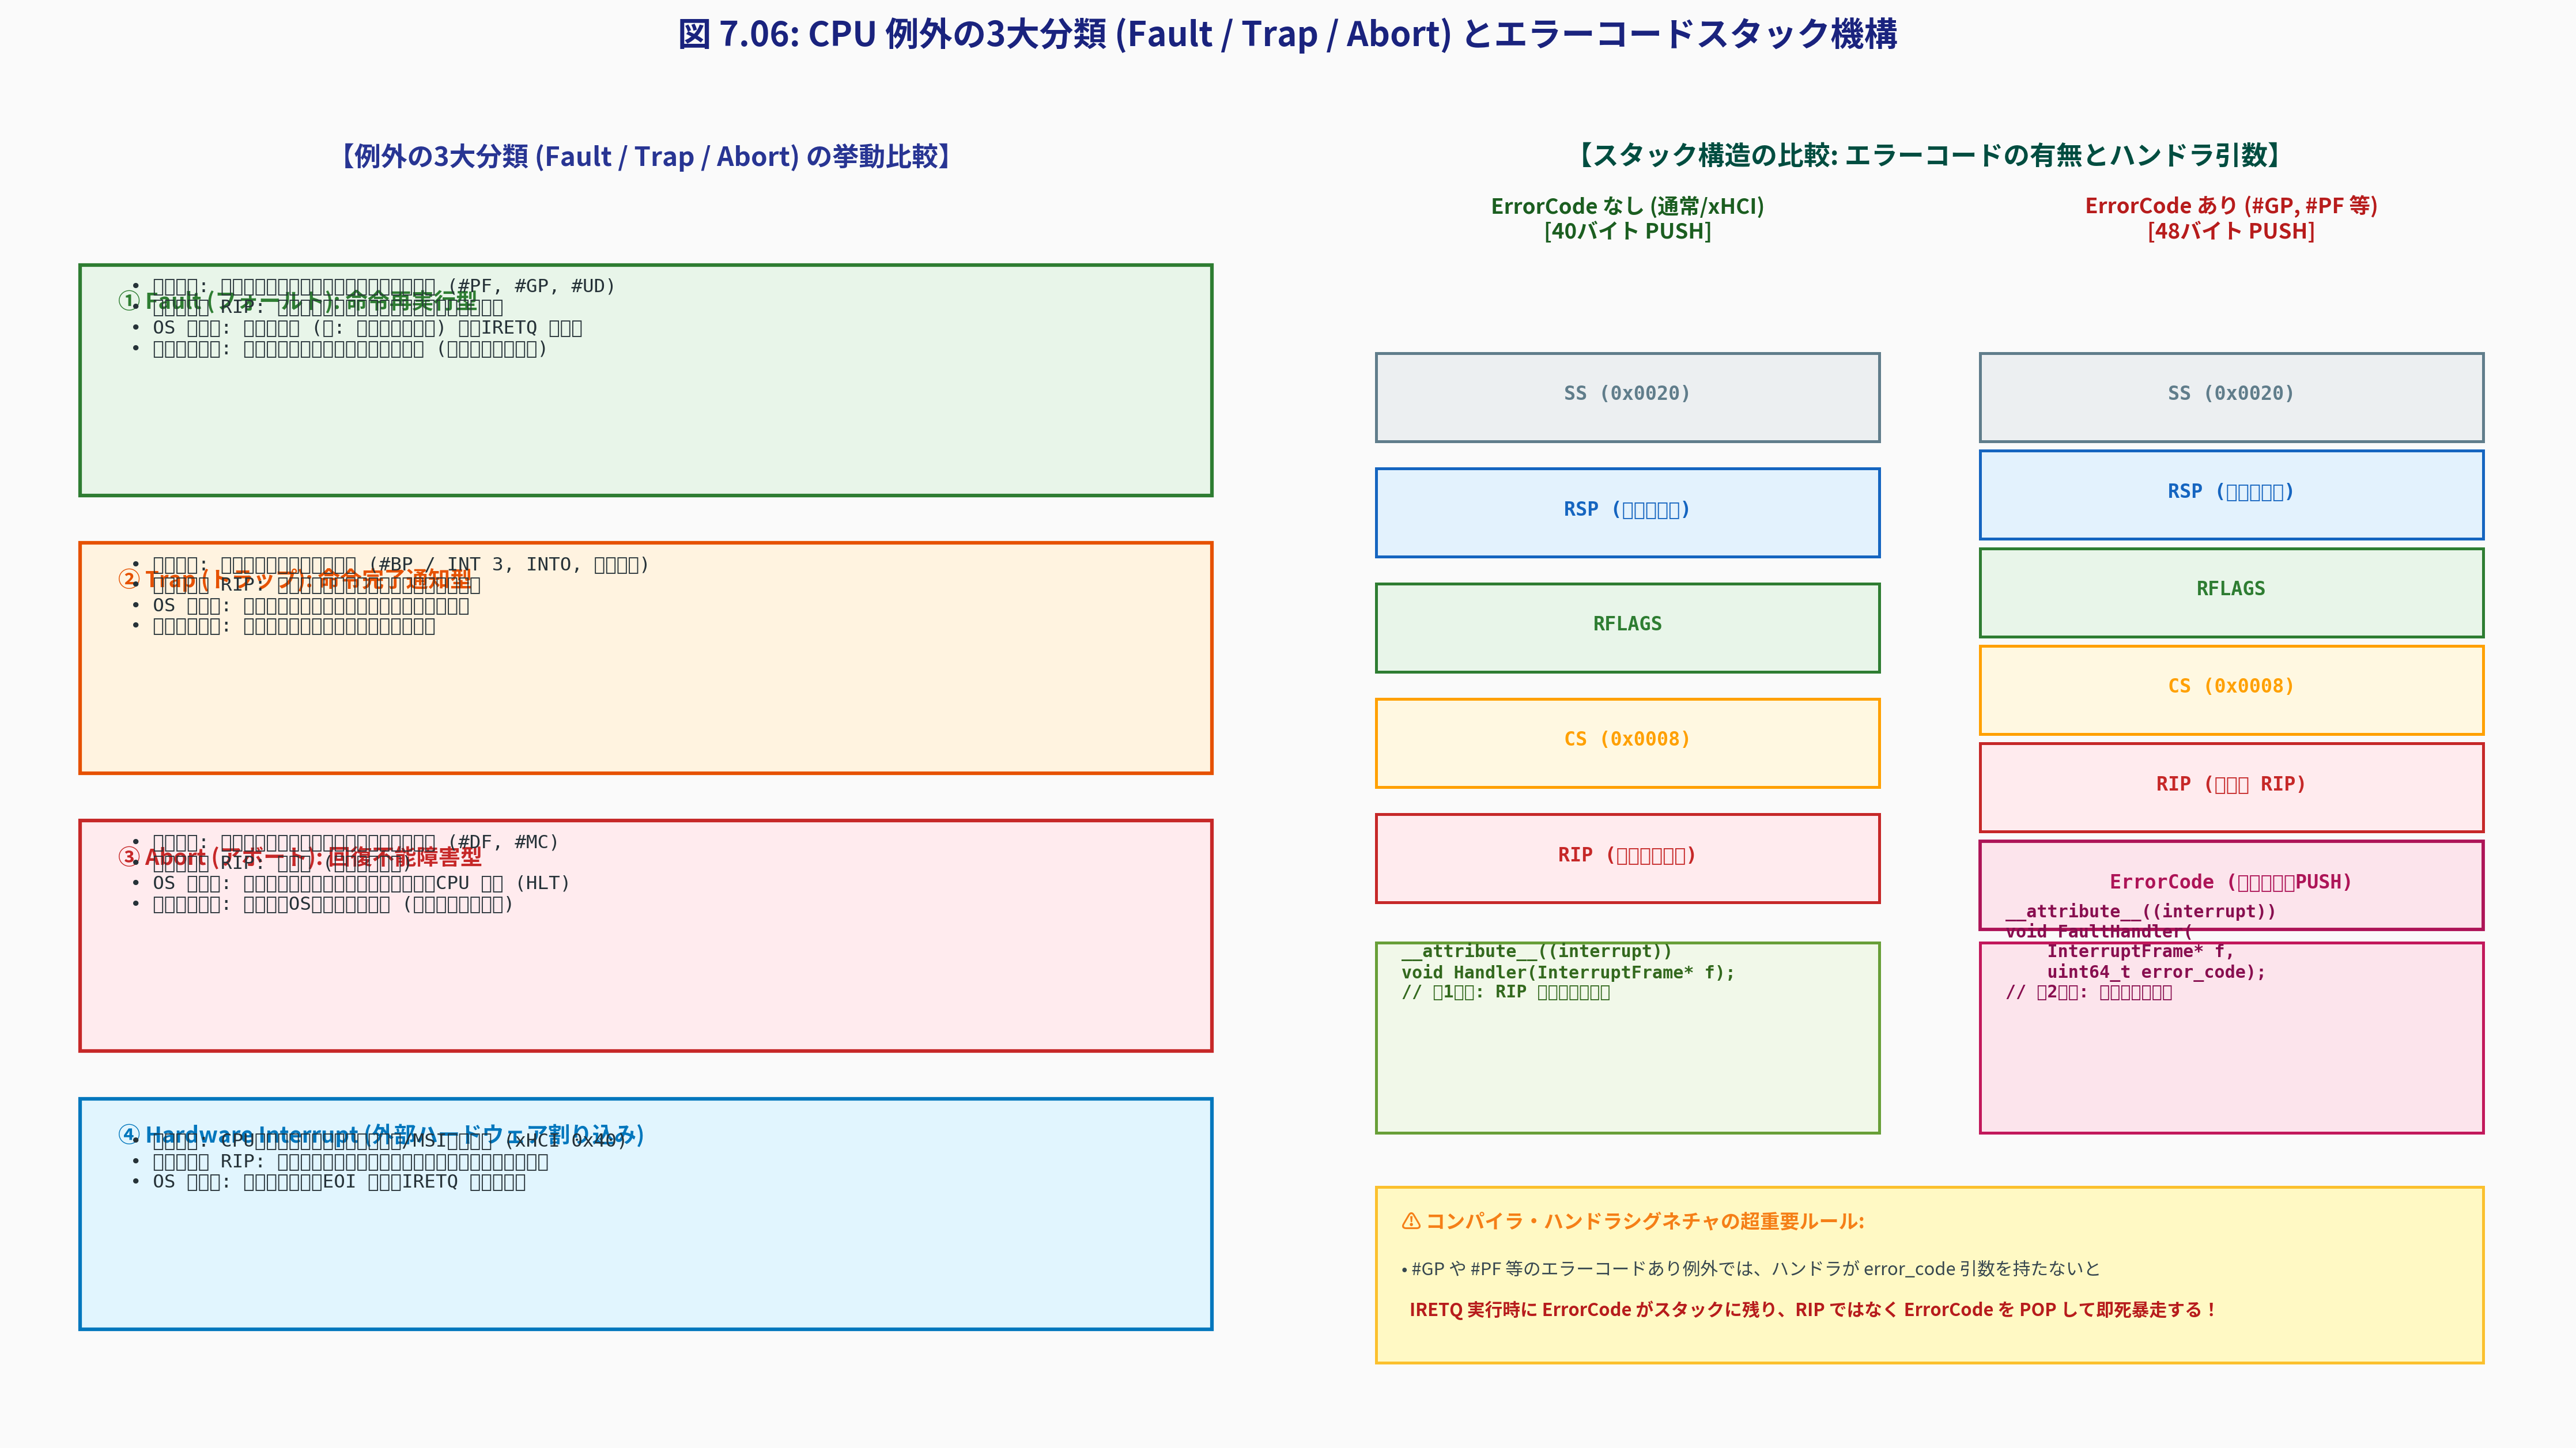

In [3]:
# === Figure 7.06: CPU 例外分類 & エラーコードスタック機構の生成 & 表示 ===
import os
import matplotlib.pyplot as plt
from common import plot_cpu_exception_types_and_handling

fig_path2 = os.path.join(repo_root, "7", "result", "fig7_06_cpu_exception_types_and_handling.png")
plot_cpu_exception_types_and_handling(fig_path2)

if os.path.exists(fig_path2):
    print(f"✅ Figure 7.06 を保存しました: {fig_path2}")
    from IPython.display import Image, display
    display(Image(filename=fig_path2, width=950))
else:
    print("❌ 画像の生成に失敗しました。")


---

## 6. MikanOS における割り込みベクタ設計 (`osbook_day07a`)

MikanOS の `kernel/interrupt.hpp` では、割り込みベクタ番号が以下のように定義されています：

```cpp
// kernel/interrupt.hpp (day07a)
class InterruptVector {
 public:
  enum Number {
    kXHCI = 0x40,
  };
};
```

### 6.1 なぜ `0x40` (十進数 64) なのか？
1. **CPU 例外領域（0〜31）との絶対的干渉回避**:
   - ベクタ 0〜31 は CPU に予約されているため、32 (`0x20`) 未満は絶対に使用できません。
2. **PC/AT レガシー互換領域（32〜63）の温存**:
   - 歴史的な 8259 PIC や BIOS/UEFI の名残がある 32〜63 番台を避け、クリーンな境界である **64 (`0x40`)** からユーザー割り込みを開始しています。
3. **後続章（タイマ・マルチタスク）への拡張性**:
   - 第11章で導入する Local APIC タイマ割り込みなど、今後追加されるハードウェア割り込みに余裕を持って連続配置できます。

### 6.2 C++ クラスによる型安全な設計
- C 言語では `#define INTR_XHCI 0x40` やグローバルな `enum` が使われがちですが、MikanOS では `InterruptVector` クラスの内部 `enum Number` として定義しています。
- これにより、`InterruptVector::kXHCI` という明確なスコープを持ち、他の定数との名前衝突を防ぎながら、コードの自己文書化を実現しています。


---

## 7. Python シミュレータによる割り込み・例外ディスパッチ検証

`common/os_sim.py` の `InterruptVectorSpace` クラスを用いて、各ベクタ番号に対するハードウェアの挙動（保存 RIP、スタック push バイト数、復帰先アドレス）を対話的にシミュレーションします。


In [4]:
# === Python によるベクタ仕様検査 & ディスパッチシミュレーション ===
from common import InterruptVectorSpace, ExceptionType

current_rip = 0x0000000000100020  # 例外・割り込みが発生した命令のアドレス
next_rip    = 0x0000000000100025  # 次の命令のアドレス

test_vectors = [
    (0,    "ゼロ除算例外 (#DE)", 0),
    (3,    "ブレークポイント (#BP)", 0),
    (8,    "ダブルフォルト (#DF)", 0),
    (13,   "一般保護例外 (#GP)", 0x20),
    (14,   "ページフォルト (#PF)", 0x02), # 書込アクセス違反
    (0x40, "MikanOS xHCI MSI 割込", 0),
]

print(f"{'Vector':<8} {'名前':<22} {'分類':<12} {'ErrorCode':<10} {'保存RIP':<18} {'復帰先':<18} {'StackPush'}")
print("-" * 100)

for vec, desc, ec in test_vectors:
    sim = InterruptVectorSpace.simulate_dispatch(vec, current_rip, next_rip, error_code_val=ec)
    ec_str = f"0x{ec:X}" if sim["has_error_code"] else "なし"
    print(f"0x{vec:02X} ({vec:<2}) {desc:<22} {sim['type']:<12} {ec_str:<10} {sim['saved_rip']:<18} {sim['return_target']:<18} {sim['stack_bytes_pushed']} bytes")


Vector   名前                     分類           ErrorCode  保存RIP              復帰先                StackPush
----------------------------------------------------------------------------------------------------
0x00 (0 ) ゼロ除算例外 (#DE)           Fault        なし         0x100020           0x100020           40 bytes
0x03 (3 ) ブレークポイント (#BP)         Trap         なし         0x100025           0x100025           40 bytes
0x08 (8 ) ダブルフォルト (#DF)          Abort        0x0        0x100020           CRASH / HALT       48 bytes
0x0D (13) 一般保護例外 (#GP)           Fault        0x20       0x100020           0x100020           48 bytes
0x0E (14) ページフォルト (#PF)          Fault        0x2        0x100020           0x100020           48 bytes
0x40 (64) MikanOS xHCI MSI 割込    Interrupt    なし         0x100025           0x100025           40 bytes


---

## 8. C++20 スタンドアロン検証コードによるメモリ構造 & 仕様の実証

`src/ch07/interrupt_vector_sim.cpp` をコンパイル・実行し、以下を検証します：
1. `InterruptVector::kXHCI == 0x40` の定数検証
2. `StandardInterruptFrame`（40 バイト）と `InterruptFrameWithErrorCode`（48 バイト）の構造体メモリレイアウトと `static_assert`
3. x86-64 CPU 例外テーブルの完全性とディスパッチシミュレーション


In [5]:
# === C++20 スタンドアロン検証コードのコンパイルと実行 ===
import subprocess, os

src_path = os.path.join(repo_root, "src/ch07/interrupt_vector_sim.cpp")
bin_path = os.path.join(repo_root, "src/ch07/interrupt_vector_sim")
cmd_compile = f"g++ -std=c++20 -O2 -Wall -Wextra -pedantic {src_path} -o {bin_path}"

print(f"🛠️ コンパイル実行: {cmd_compile}")
res_compile = subprocess.run(cmd_compile, shell=True, capture_output=True, text=True)

if res_compile.returncode == 0:
    print("✅ コンパイル成功！バイナリを実行します...\n")
    res_run = subprocess.run([bin_path], capture_output=True, text=True)
    print(res_run.stdout)
    if res_run.stderr:
        print("⚠️ 標準エラー出力:\n", res_run.stderr)
else:
    print("❌ コンパイル失敗:\n", res_compile.stderr)


🛠️ コンパイル実行: g++ -std=c++20 -O2 -Wall -Wextra -pedantic /home/student/Documents/GitHub/study-mikanos/src/ch07/interrupt_vector_sim.cpp -o /home/student/Documents/GitHub/study-mikanos/src/ch07/interrupt_vector_sim


✅ コンパイル成功！バイナリを実行します...

  MikanOS Chapter 7.3: x86-64 Interrupt Vectors C++20 Verification

[Test 1] Verifying Vector Space Partitioning & Constants...
  ✓ Vector 0-31 classified as CPU Exceptions.
  ✓ Vector 32-255 classified as User Defined.
  ✓ MikanOS InterruptVector::kXHCI == 0x40 (64) verified.

[Test 2] Verifying CPU Exception Specifications...
  ✓ #DE (0), #BP (3), #DF (8), #GP (13), #PF (14) specs match Intel SDM Vol.3A.

[Test 3] Verifying Dispatch Simulation for Fault / Trap / Abort / Hardware Interrupt...
  ✓ Fault preserves current RIP (0x100020) for re-execution.
  ✓ Trap & Hardware Interrupt save next RIP (0x100025) for normal progression.
  ✓ Abort safely identifies system unrecoverability.
  ✓ Stack size difference correctly calculated: 40 bytes (standard) vs 48 bytes (with ErrorCode).

------------------------------------------------------------------
Summary Table of Key Vectors & MikanOS Interrupt Architecture:
------------------------------------------------------

---

## 9. 本節のまとめと次節（7.4 割り込み記述子の設定）への展開

### 9.1 本節で学んだ重要事項
1. **割り込みベクタ番号（0〜255）の役割**:
   - CPU が割り込み要因を識別するための 8 ビットの数値インデックス。
   - ベクタ 0〜31 は CPU アーキテクチャ定義例外（予約領域）、ベクタ 32〜255 は OS が自由に使える領域。
2. **CPU 例外の 3 大分類**:
   - **Fault**: 命令再実行型（保存 RIP = 自命令）。原因解決後に同一命令を再実行できる。
   - **Trap**: 命令完了通知型（保存 RIP = 次命令）。
   - **Abort**: 回復不能型（保存 RIP = 不確定）。
3. **ハードウェアエラーコードの罠**:
   - `#GP` や `#PF` などの特定例外では、CPU が 64 ビットのエラーコードをスタックに自動 push する（計 48 バイト）。
   - `__attribute__((interrupt))` ハンドラに `(InterruptFrame*, uint64_t error_code)` の第2引数を指定しないとスタックが破壊される。
4. **MikanOS のベクタ設計**:
   - xHCI ホストコントローラの MSI 割り込みとして `0x40` (64) を採用し、例外領域やレガシー領域との衝突を完全に回避。

---

### 9.2 次節への展開: 7.4 割り込み記述子の設定 (`7/7.4_Configuring_IDT_Descriptors.ipynb`)
ベクタ番号が決まり、ハンドラ関数が用意できたら、次は **「ベクタ番号とハンドラ関数を結びつける表（IDT: Interrupt Descriptor Table）」** を CPU に登録しなければなりません。

次節では、16 バイトの `InterruptDescriptor` 構造体のビットフィールド設計（オフセット分割、セグメントセレクタ、属性、DPL、Present ビット）と、CPU に IDT を認識させる `LIDT`（*Load IDT*）アセンブリ命令の仕組みを徹底解明します！
